# 06 - Model Comparison
Reads the metrics saved by notebooks 01 to 05 and plots them. Run notebooks 00 to 05 first.

In [1]:
import os, json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = os.path.abspath('..')
ART = os.path.join(ROOT, 'artifacts')
IMG = os.path.join(ROOT, 'images')
os.makedirs(IMG, exist_ok=True)

files = ['logistic_regression', 'decision_tree', 'knn', 'naive_bayes', 'random_forest']
rows = [json.load(open(os.path.join(ART, f'metrics_{f}.json'))) for f in files]
results = pd.DataFrame(rows).set_index('model')
results.index.name = 'ML Model Name'
results

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.7945,0.8431,0.6798,0.4663,0.5532,0.4385
Decision Tree,0.7636,0.8755,0.5428,0.8441,0.6607,0.5204
kNN,0.8050,0.8435,0.6733,0.5535,0.6075,0.4835
Naive Bayes,0.7393,0.7435,0.6939,0.0787,0.1414,0.1690
Random Forest (Ensemble),0.8061,0.8956,0.6066,0.8220,0.6981,0.5740


## Comparison table (for README)

In [2]:
print(results.to_markdown(floatfmt='.4f'))
results.to_csv(os.path.join(ART, 'comparison.csv'))

| ML Model Name            |   Accuracy |    AUC |   Precision |   Recall |     F1 |    MCC |
|:-------------------------|-----------:|-------:|------------:|---------:|-------:|-------:|
| Logistic Regression      |     0.7945 | 0.8431 |      0.6798 |   0.4663 | 0.5532 | 0.4385 |
| Decision Tree            |     0.7636 | 0.8755 |      0.5428 |   0.8441 | 0.6607 | 0.5204 |
| kNN                      |     0.8050 | 0.8435 |      0.6733 |   0.5535 | 0.6075 | 0.4835 |
| Naive Bayes              |     0.7393 | 0.7435 |      0.6939 |   0.0787 | 0.1414 | 0.1690 |
| Random Forest (Ensemble) |     0.8061 | 0.8956 |      0.6066 |   0.8220 | 0.6981 | 0.5740 |


## Bar chart of all metrics

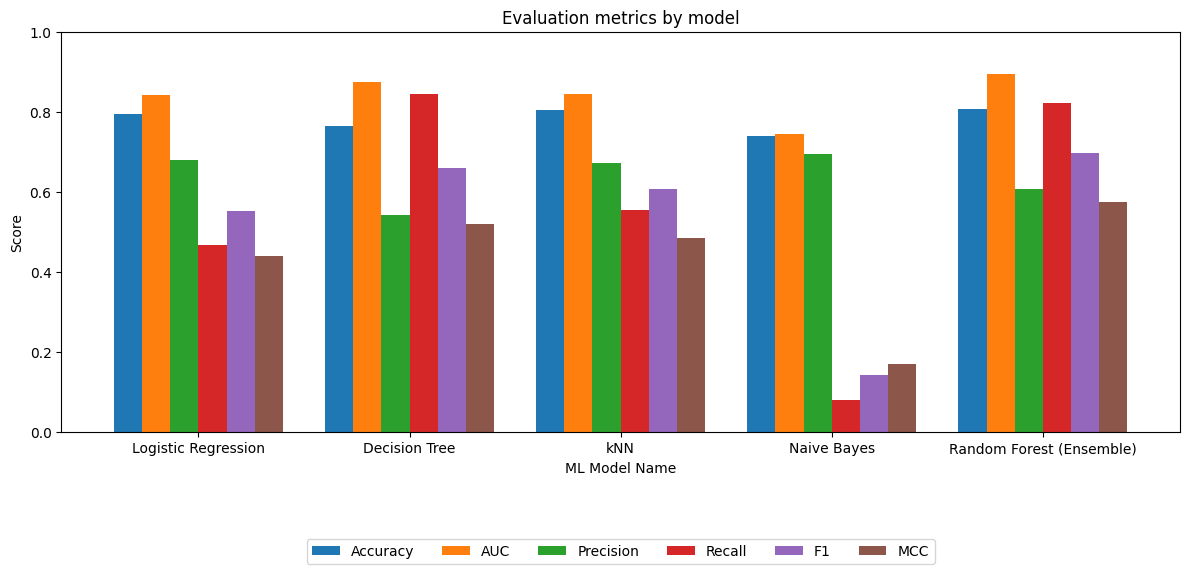

In [3]:
ax = results.plot(kind='bar', figsize=(12, 6), width=0.8)
ax.set_title('Evaluation metrics by model')
ax.set_ylabel('Score')
ax.set_ylim(0, 1)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=6)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(IMG, 'metrics_bar.png'), dpi=120)
plt.show()

## Heatmap

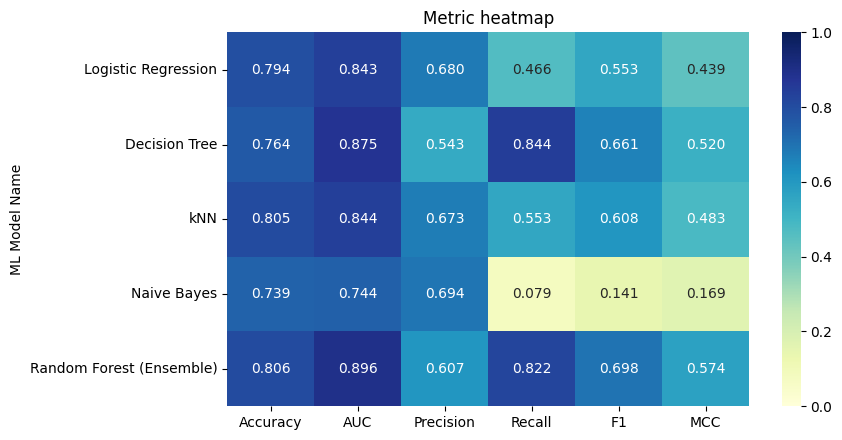

In [4]:
plt.figure(figsize=(9, 4.5))
sns.heatmap(results, annot=True, fmt='.3f', cmap='YlGnBu', vmin=0, vmax=1)
plt.title('Metric heatmap')
plt.tight_layout()
plt.savefig(os.path.join(IMG, 'metrics_heatmap.png'), dpi=120)
plt.show()

## Best model per metric

In [5]:
pd.DataFrame({'Best model': results.idxmax(), 'Score': results.max()})

,Best model,Score
Accuracy,Random Forest (Ensemble),0.8061
AUC,Random Forest (Ensemble),0.8956
Precision,Naive Bayes,0.6939
Recall,Decision Tree,0.8441
F1,Random Forest (Ensemble),0.6981
MCC,Random Forest (Ensemble),0.5740
